`28/09/2026`

# TCC Plots

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import AutoMinorLocator

plt.style.use('Ltx.mplstyle')

In [2]:
figs_folder = "./figures/"

In [3]:
Perc7_DKBLUE_1 = '#340498'
Perc7_PURPUR_2 = '#6c00a8'
Perc7_VIOLET_3 = '#a31d99'
Perc7_PINKSH_4 = '#ca4678'
Perc7_AMBERS_5 = '#e97257'
Perc7_ORANGE_6 = '#fa9f3a'
Perc7_YELLOW_7 = '#f8db24'

Perc7 = [Perc7_DKBLUE_1, Perc7_PURPUR_2, Perc7_VIOLET_3, Perc7_PINKSH_4, Perc7_AMBERS_5, Perc7_ORANGE_6, Perc7_YELLOW_7]

Perc5_DKBLUE_1 = '#340498'
Perc5_PURPLE_2 = '#7e03a7'
Perc5_PINKSH_3 = '#b83289'
Perc5_ROSSEE_4 = '#de6063'
Perc5_ORANGE_5 = '#f8983d'

Perc5 = [Perc5_DKBLUE_1, Perc5_PURPLE_2, Perc5_PINKSH_3, Perc5_ROSSEE_4, Perc5_ORANGE_5]
Perc5_reverse = Perc5[::-1]


In [4]:
# Physical units
cm = 1 / 2.54

# Report dimensions
WIDTH = {
    "single": 15 * cm,
    "double": 15 * cm,
    "triple": 15 * cm,
    "half": 7.2 * cm,
}

HEIGHT = {
    "single": 9.0 * cm,
    "double": 6.5 * cm,
    "triple": 5.5 * cm,
    "half": 5.0 * cm,
}

def figure(kind="single", aspect=0.65, **kwargs):
    """Create a report-sized figure.

    aspect = height / width
    """
    return plt.subplots(
        figsize=(WIDTH[kind], WIDTH[kind] * aspect),
        layout="constrained",
        **kwargs,
    )

In [5]:
def apply_axis_style(ax, tick_len=5):
    # if ax.get_xscale() != "log":
    #     ax.xaxis.set_minor_locator(AutoMinorLocator())
    # if ax.get_yscale() != "log":
    #     ax.yaxis.set_minor_locator(AutoMinorLocator())
    # ax.tick_params(which='both', direction='in', right=True, top=True)
    # ax.tick_params(which='major', length=tick_len)
    try:
        ax.get_yticklabels()[0].set_verticalalignment("bottom")
        ax.get_yticklabels()[-1].set_verticalalignment("top")
    except (IndexError, AttributeError):
        pass
    try:
        ax.get_xticklabels()[0].set_horizontalalignment("left")
        ax.get_xticklabels()[-1].set_horizontalalignment("right")
    except (IndexError, AttributeError):
        pass

In [6]:
from emerald.classical.dynamics import StaticDynamics
from emerald.potentials import Coulomb, Morse, MorseSoftCoulomb, SoftCoulomb


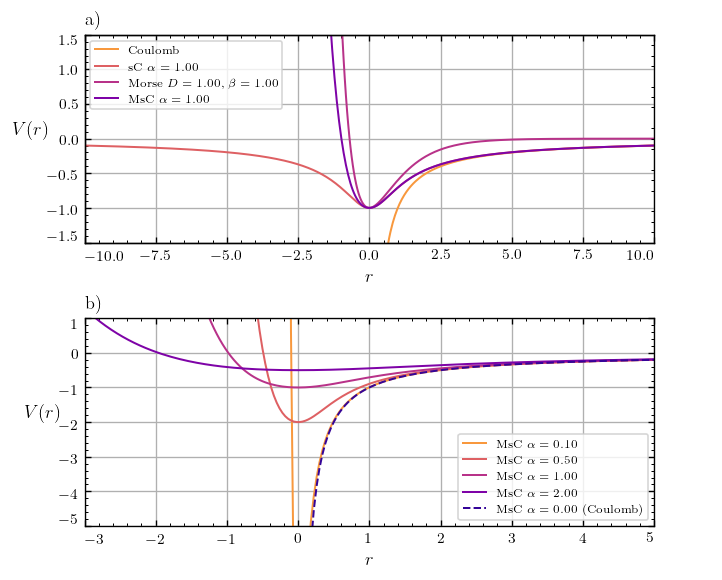

In [7]:
## Figure 1

msc = MorseSoftCoulomb(alpha=1)
sc  = SoftCoulomb(alpha=1)
cou = Coulomb()
mor = Morse(D=1, beta=1)

fig1, (ax1_1, ax1_2) = figure("double", 0.8, nrows=2)

r_grid = np.linspace(-10, 10, 500)

# Panel a)

ax1_1.set_title("a)", loc='left', weight='bold')
for p, pot in enumerate([cou, sc, mor, msc]):
    ax1_1.plot(r_grid, pot(r_grid), c=Perc5_reverse[p], label=f"{pot.print(short=True, latex=True)}")
ax1_1.legend(loc='upper left')
ax1_1.grid(which='major')
ax1_1.set_xlim(-10, 10)
ax1_1.set_ylim(-1.5, 1.5)
apply_axis_style(ax1_1)

# Panel b)

ax1_2.set_title("b)", loc='left', weight='bold')
for i, _a in enumerate([0.1, 0.5, 1, 2]):
    msc = MorseSoftCoulomb(_a)
    ax1_2.plot(r_grid, msc(r_grid), c=Perc5_reverse[i], label=f"{msc.print(short=True, latex=True)}")
ax1_2.plot(r_grid, cou(r_grid), c=Perc5[0], ls='dashed', label=r"MsC $\alpha=0.00$ (Coulomb)")

ax1_2.legend(loc='lower right')
ax1_2.grid(which='major')
ax1_2.set_xlim(-3, 5)
ax1_2.set_ylim(-5, 1)
apply_axis_style(ax1_2)

# remaining labels
for _ax in [ax1_1, ax1_2]:
    _ax.set_xlabel("$r$")
    _ax.set_ylabel("$V(r)$", rotation=0, labelpad=10)

# whitespace on the right

ax2 = ax1_1.twinx()
ax2.set_ylabel(
    r"$\mathrm{placeholder}$",
    color="none",
    rotation=0
)
ax2.tick_params(
    right=False,
    labelright=False
)
ax2.spines["right"].set_visible(False)

In [8]:
fig1.savefig(f"{figs_folder}Fig1.pdf")

/media/gabriel/AcerD/Documentos/cursos/IC/Morse-Coulomb/Dev/src/emerald/potentials/morse.py:55: RuntimeWarning: divide by zero encountered in log
  rM = -(1/self.beta)*np.log(1 - delta)
/media/gabriel/AcerD/Documentos/cursos/IC/Morse-Coulomb/Dev/src/emerald/potentials/morse.py:55: RuntimeWarning: invalid value encountered in log
  rM = -(1/self.beta)*np.log(1 - delta)


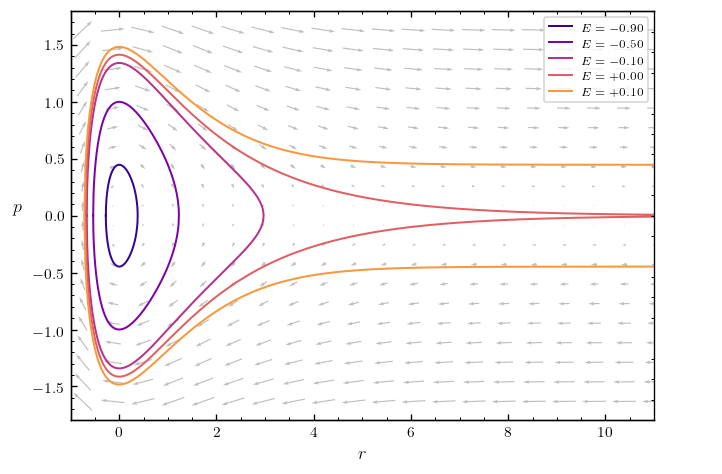

In [ ]:
## Figure 2

mor = Morse(D=1, beta=1)

fig2, ax2 = figure("single", 0.65)

r_vals = np.linspace(-0.75, 11, 20)     # shape (20,)
p_max = mor.momentum(E=0.1, r=0)
p_vals = np.linspace(-1.1*p_max, 1.1*p_max, 20)     #shape (20,)
R, P = np.meshgrid(r_vals, p_vals)  # shapes (20, 20) & (20, 20)

fake_mor = Morse(D=1, beta=0.5)
dyn = StaticDynamics(fake_mor)
X = np.column_stack((R.reshape(R.size, 1), P.reshape(P.size, 1)))   
# ^ shape (400, 2) every (r, p) permutation
Y = dyn.dstate(0, X) # shape (400, 2), maps every (r, p) position to (ṙ, ṗ)
U = Y[:, 0].reshape(R.shape)    #back to (20, 20) of ṙ values
V = Y[:, 1].reshape(R.shape)    #back to (20, 20) of ṗ values

# plot the arrows
ax2.quiver(R, P, U, V, angles='xy', pivot='middle', color='grey', alpha=.5, scale=40, width=0.002)


r_grid = np.linspace(-1, 11, 500)

for i, _E in enumerate([-0.9, -0.5, -0.1, 0, 0.1]):
    ax2.plot(*mor.phase_space(_E, 500, r2=11), label=f"$E={_E:+.2f}$")
ax2.legend(loc='upper right')
# ax1_1.grid(which='major')
ax2.set_xlim(-1, 11)
# ax2.set_ylim(-2, 2)

ax2.set_xlabel("$r$")
ax2.set_ylabel("$p$", rotation=0, labelpad=10)
# apply_axis_style(ax2)

# whitespace on the right

ax2r = ax2.twinx()
ax2r.set_ylabel(
    r"$\mathrm{placeholder}$",
    color="none",
    rotation=0
)
ax2r.tick_params(
    right=False,
    labelright=False
)
ax2r.spines["right"].set_visible(False)

In [10]:
fig2.savefig(f"{figs_folder}Fig2.pdf")

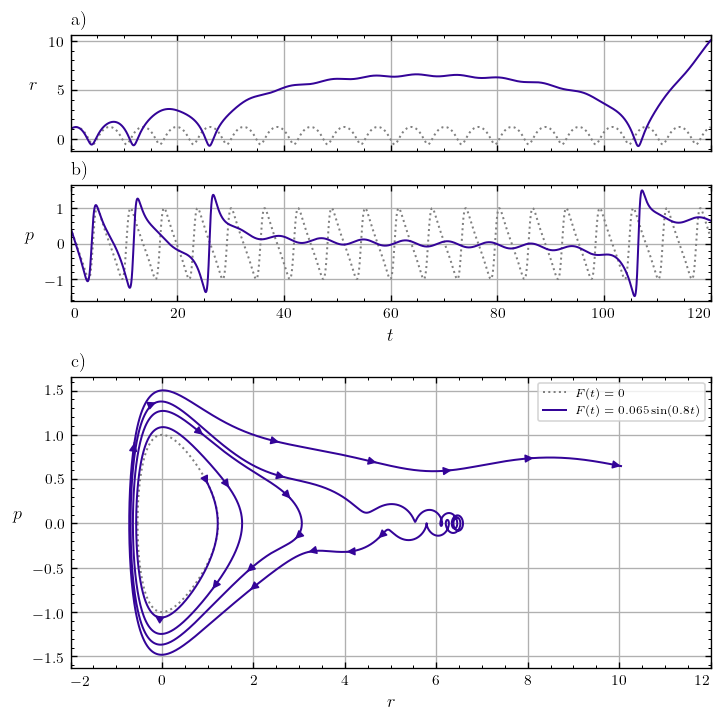

In [55]:
## Figure 3

from emerald.classical.dynamics import Dynamics
from emerald.fields import SinusoidField



mor = Morse(D=1, beta=1)
fld = SinusoidField(0.065, 0.8, 0)

fig3, (ax3_1, ax3_2, ax3_3) = figure("double", 1, nrows=3, gridspec_kw={"height_ratios": [1, 1, 2.5]})

static_dyn = StaticDynamics(mor)
dyn = Dynamics(mor, fld)

# times = np.linspace(0, 14.5*fld.period, 10000)
times = np.linspace(0, 120, 10000)
r0 = 1
state0 = np.array([r0, mor.momentum(E=-0.5, r=r0)])

traj_static = static_dyn.propagate(state0, t_span=(times[0], times[-1]), t_eval=times)
traj = dyn.propagate(state0, t_span=(times[0], times[-1]), t_eval=times)

ax3_1.plot(traj_static.time, traj_static.position, ls='dotted', c='grey')
ax3_1.plot(traj.time, traj.position)
ax3_1.set_title("a)", loc='left', weight='bold')
ax3_1.set_ylabel("$r$", rotation=0, labelpad=10)
ax3_1.tick_params(labelbottom=False)
ax3_1.set_xlim(traj.time[0], traj.time[-1])

ax3_2.plot(traj_static.time, traj_static.momentum, ls='dotted', c='grey')
ax3_2.plot(traj.time, traj.momentum)
ax3_2.set_title("b)", loc='left', weight='bold')
ax3_2.set_ylabel("$p$", rotation=0, labelpad=10)
ax3_2.set_xlabel("$t$")
ax3_2.set_xlim(traj.time[0], traj.time[-1])
ax3_2.sharex(ax3_1)

# add arrows indicating trajectory direction
arrows = 20
# concentrate arrows at start and end of trajectory
arrow_indices = np.concatenate((
    np.linspace(1, len(traj.time)//4, arrows//2, dtype=int),
    np.linspace(4*len(traj.time)//5, len(traj.time)-1, arrows//2, dtype=int)
))
for i in arrow_indices:
    ax3_3.annotate(
        '',
        xy=(traj.position[i], traj.momentum[i]),
        xytext=(traj.position[i-1], traj.momentum[i-1]),
        arrowprops={'arrowstyle': '-|>', 'color': Perc5_DKBLUE_1, 'lw': 0.9},
        size=10,
    )

ax3_3.set_title("c)", loc='left', weight='bold')
ax3_3.plot(*mor.phase_space(-0.5, N=500), ls='dotted', c='grey', label="$F(t)=0$")
ax3_3.plot(traj.position, traj.momentum, label=r"$F(t)=0.065\sin(0.8 t)$")
ax3_3.set_ylabel("$p$", rotation=0, labelpad=10)
ax3_3.set_xlabel("$r$")
ax3_3.set_xlim(-2, 12)
ax3_3.legend(loc='upper right')

for _ax in (ax3_1, ax3_2, ax3_3):
    _ax.grid(which='major')
    apply_axis_style(_ax)



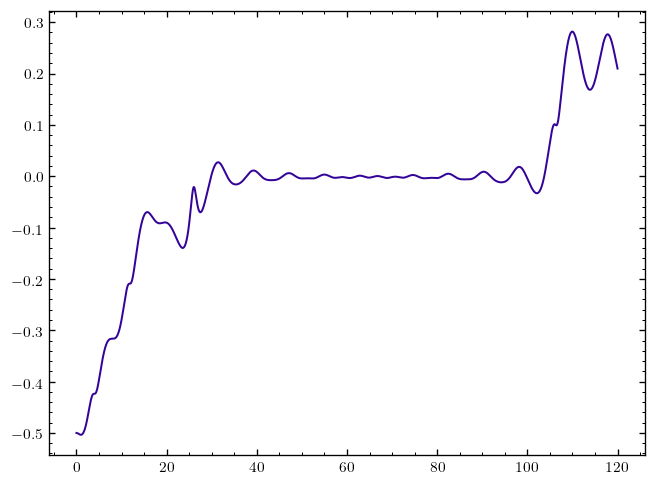

In [56]:
plt.plot(traj.time, traj.energy)

/tmp/ipykernel_11308/910066329.py:10: RuntimeWarning: divide by zero encountered in divide
  ax4_1.plot(rs, 1/mor.momentum(_E, rs), label=rf"$E = {_E:+.1f}$")
/media/gabriel/AcerD/Documentos/cursos/IC/Morse-Coulomb/Dev/src/emerald/potentials/base.py:138: RuntimeWarning: invalid value encountered in scalar divide
  return dr_dphi / self.momentum(E, r)
/media/gabriel/AcerD/Documentos/cursos/IC/Morse-Coulomb/Dev/src/emerald/potentials/base.py:138: RuntimeWarning: divide by zero encountered in scalar divide
  return dr_dphi / self.momentum(E, r)


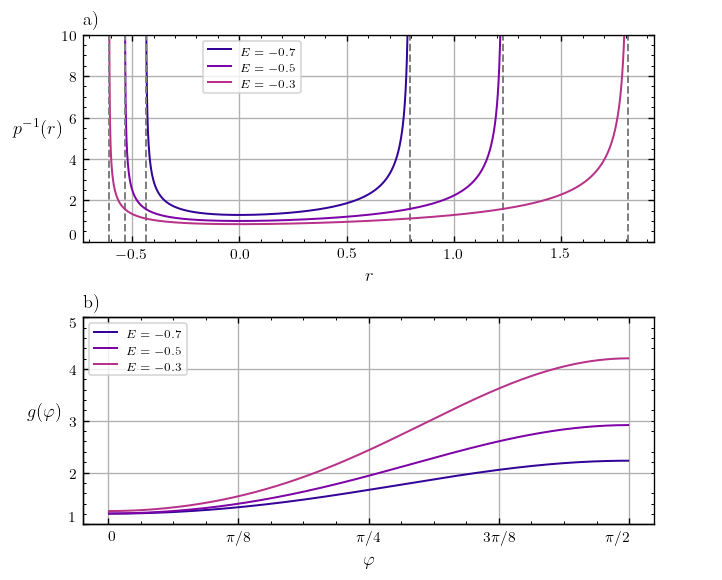

In [39]:
fig4, (ax4_1, ax4_2) = figure("double", 0.8, nrows=2)


phis = np.linspace(0, np.pi/2, 500)


for _E in [-0.7, -0.5, -0.3]:
    rm, rM = mor.turning_points(_E)
    rs = np.linspace(rm, rM, 2000)
    ax4_1.plot(rs, 1/mor.momentum(_E, rs), label=rf"$E = {_E:+.1f}$")
    ax4_1.axvline(rm, c='grey', ls='dashed')
    # ax4_1.text(
    #     rm, 1, r'$r_{-}$',
    #     ha='center', va='bottom',
    #     bbox={'facecolor': 'white', 
    #           'edgecolor': 'none',
    #           'pad': 2}
    # )

    ax4_1.axvline(rM, c='grey', ls='dashed')
    # ax4_1.text(
    #     rM, 1, r'$r_{+}$',
    #     ha='center', va='bottom',
    #     bbox={'facecolor': 'white', 
    #           'edgecolor': 'none',
    #           'pad': 2}
    # )

ax4_1.set_xlabel('$r$')
ax4_1.set_ylabel(r'$p^{-1}(r)$', rotation=0, labelpad=15)
ax4_1.set_title('a)', loc='left', weight='bold')
ax4_1.legend(loc='upper left',
    bbox_to_anchor=(0.2, 1.0))
apply_axis_style(ax4_1)

ax4_1.grid(True)
ax4_1.set_ylim(0, 10)

for _E in [-0.7, -0.5, -0.3]:
    rm, rM = mor.turning_points(_E)
    integs = np.array([mor._inv_momentum_integrand(phi, _E, rm, rM) for phi in phis])
    ax4_2.plot(phis[1:-1], integs[1:-1], label=rf"$E = {_E:+.1f}$")

ax4_2.legend()
ax4_2.set_xlabel(r'$\varphi$')
ax4_2.set_ylabel(r'$g(\varphi)$', rotation=0, labelpad=15)
ax4_2.set_title('b)', loc='left', weight='bold')
ax4_2.set_xticks(np.array([0, np.pi/8, np.pi/4, 3*np.pi/8, np.pi/2]))
ax4_2.set_xticklabels(['0', r'$\pi/8$', r'$\pi/4$', r'$3\pi/8$', r'$\pi/2$'])
ax4_2.set_ylim(1, 5)
ax4_2.grid(True)
apply_axis_style(ax4_2)

ax4r = ax4_2.twinx()
ax4r.set_ylabel(
    r"$\mathrm{placeholder}$",
    color="none",
    rotation=0
)
ax4r.tick_params(
    right=False,
    labelright=False
)
ax4r.spines["right"].set_visible(False)

In [41]:
from emerald.potentials.base import Potential
import numpy as np
from scipy.integrate import cumulative_trapezoid


def angle_grid(
    potential: "Potential",
    E_range,
    M: int = 300,
    NQ: int = 500,
):
    """
    Calculate the angle grid theta(E, phi) used for interpolation.

    Parameters
    ----------
    potential : Potential
        Potential instance providing turning_points(E),
        angular_frequency(E), and _inv_momentum_integrand(...).
    E_range : array_like
        Energies defining the range of the grid. The minimum and
        maximum bound energies determine the energy interval.
    M : int, default=300
        Number of energy grid points.
    NQ : int, default=500
        Number of phi grid points.

    Returns
    -------
    E_grid : ndarray, shape (M,)
        Energy grid.
    phi_table : ndarray, shape (NQ,)
        Phi grid, spanning [0, pi/2].
    theta_grid : ndarray, shape (M, NQ)
        Angle values evaluated on the (E, phi) grid.
    """
    E_range = np.asarray(E_range, dtype=float)
    E_range = E_range[np.isfinite(E_range) & (E_range < 0)]

    if E_range.size == 0:
        raise ValueError("E_range must contain at least one bound energy.")

    E_grid = np.linspace(E_range.min(), E_range.max(), M)
    phi_table = np.linspace(0.0, np.pi / 2, NQ)

    rm = np.empty(M)
    rM = np.empty(M)
    omg = np.empty(M)

    for k, Ek in enumerate(E_grid):
        rm[k], rM[k] = potential.turning_points(Ek)
        omg[k] = potential.angular_frequency(Ek)

    with np.errstate(divide="ignore", invalid="ignore"):
        integrand = potential._inv_momentum_integrand(
            phi_table[None, :],
            E_grid[:, None],
            rm[:, None],
            rM[:, None],
        )

    # Regularize the endpoint as in the original implementation.
    integrand[:, 0] = integrand[:, 1]

    cum = cumulative_trapezoid(
        integrand,
        phi_table,
        axis=1,
        initial=0.0,
    )

    theta_grid = omg[:, None] * cum

    return E_grid, phi_table, theta_grid


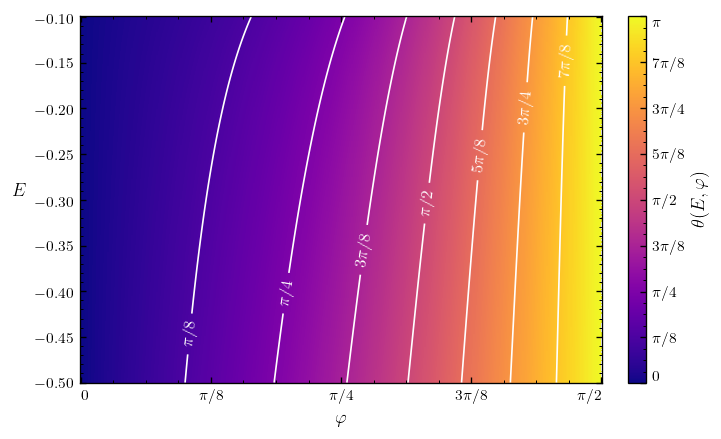

In [79]:
E_grid, phi_grid, theta_grid = angle_grid(
    mor,
    E_range=(-0.5, -0.1),
)

E_mesh, phi_mesh = np.meshgrid(E_grid, phi_grid, indexing="ij")

fig_grid, ax_grid = figure("single", 0.6)

levels = np.arange(np.pi/8, np.pi, np.pi/8)

pcm = ax_grid.pcolormesh(
    phi_mesh,
    E_mesh,
    theta_grid,
    shading="auto",
    cmap="plasma",
    rasterized=True,
)

levs = ax_grid.contour(
    phi_mesh,
    E_mesh,
    theta_grid,
    levels=levels,
    colors='w',
    linewidths=1
)

level_labels = {
    np.pi/8: r"$\pi/8$",
    np.pi/4: r"$\pi/4$",
    3*np.pi/8: r"$3\pi/8$",
    np.pi/2: r"$\pi/2$",
    5*np.pi/8: r"$5\pi/8$",
    3*np.pi/4: r"$3\pi/4$",
    7*np.pi/8: r"$7\pi/8$",
}

x_pos = np.array([np.pi/8, 3*np.pi/16 ,np.pi/4, 5*np.pi/16 ,3*np.pi/8, 7*np.pi/16 ,np.pi/2])
y_pos = np.linspace(-0.45, -0.15, 7)

pos = list(zip(x_pos, y_pos))

clab = ax_grid.clabel(levs, inline=True, fontsize=10, fmt=level_labels, manual=pos, )

ax_grid.set_xlabel(r"$\varphi$")
ax_grid.set_ylabel(r"$E$", rotation=0, labelpad=10)

ax_grid.set_xticks(np.arange(0, np.pi/2+np.pi/8, np.pi/8))
ax_grid.set_xticklabels(['0', r'$\pi/8$', r'$\pi/4$', r'$3\pi/8$', r'$\pi/2$'])


cbar = fig_grid.colorbar(pcm, ax=ax_grid, label=r"$\theta(E,\varphi)$")
cbar.set_ticks(np.arange(0, np.pi+np.pi/8, np.pi/8))
cbar.set_ticklabels(['0', r'$\pi/8$', r'$\pi/4$', r'$3\pi/8$', r'$\pi/2$', 
                     r'$5\pi/8$', r'$3\pi/4$', r'$7\pi/8$', r'$\pi$'])

apply_axis_style(ax_grid)

cbar.ax.get_yticklabels()[0].set_verticalalignment("bottom")
cbar.ax.get_yticklabels()[-1].set_verticalalignment("top")


In [80]:
fig_grid.savefig(f"{figs_folder}Fig-Grid.pdf")

In [40]:
fig4.savefig(f"{figs_folder}Fig4.pdf")

In [20]:
(np.pi/2 + np.pi/4)/2, 3*np.pi/8

(1.1780972450961724, 1.1780972450961724)

$^{-d}/_2$